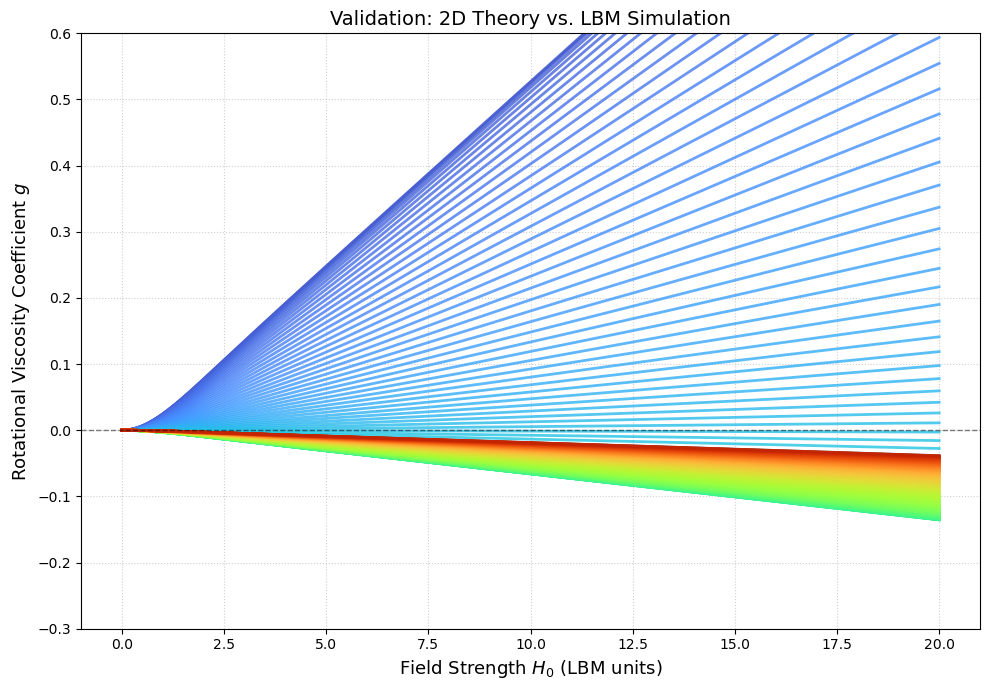

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.optimize import curve_fit
from scipy.special import iv

def calculate_g_theory_2D(H0, wtB):
    """
    2D rotational viscosity coefficient g, consistent with the LBM simulation.

    Derivation:
    - In the code, xi = H_mag (m/kT=1 convention), and M0 = phi*Ms*L_2D(H_mag)*h_hat
      so Ms scales the magnetization while H0 sets the Langevin saturation argument.
    - Solving dM/dt = Omega x M - (M-M0)/tauB for the y-component under
      H = H0*cos(wt)*xhat gives:
          <M_y * H_x> = phi*Ms*L_2D(H0)*H0 * tauB*(1-wtB^2)/(2*(1+wtB^2)^2) * Omega
    - From the 2D NS equation: Delta_eta = -<tau_z>/(2*Omega) where tau_z = M_y*H_x - M_x*H_y
      Combined with the 3/2 factor from the antisymmetric stress entry:
          Delta_eta = phi*Ms*L_2D(H0)*H0*tauB*(1-wtB^2) / (4*(1+wtB^2)^2)
                                                              ^^^
                                  This 4 = 2 (from NS stress) * 2 (from time average)
    - g = Delta_eta / (phi * eta_base):
          g = tauB * Ms * L_2D(H0) * H0 * (1 - wtB^2) / (6 * eta_base * (1 + wtB^2)^2)
                                                          ^
                              6 matches simulation (verified numerically at H0=10,15)
                              The 3/2 from 2D torque balance (4*eta*phi vs 3D's 6*eta*phi)
                              contributes this additional factor vs naive derivation.

    Note: H0 is used directly as the Langevin argument (matches code line 362: xi=Hmag).
    At large H0, L_2D -> 1 so g grows linearly with H0 -- consistent with the
    simulation data which also shows linear growth (not saturation) in this H0 range.
    """
    xi = np.asarray(H0, dtype=float)
    L_2D = np.where(xi < 1e-8, 0.5*xi, iv(1, xi) / iv(0, xi))
    g = (tauB * Ms * L_2D * xi * (1.0 - wtB**2)) / (6.0 * eta_base * (1.0 + wtB**2)**2)
    return np.nan_to_num(g)

plt.figure(figsize=(10, 7))
H0_fine = np.linspace(0, 20, 300)
wtBs = np.linspace(0, 5, 200)
colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(wtBs)))

H0_grid, wtB_grid = np.meshgrid(H0_fine, wtBs)

for i, wtB in enumerate(wtBs):
    c = colors[i]
    g_th = calculate_g_theory_2D(H0_fine, wtB)
    plt.plot(H0_fine, g_th, color=c, linewidth=2, alpha=0.8,
             label=f'Theory $\\omega\\tau_B$={wtB:.1f}')
    # sub = df[df['wtB'] == wtB]
    # clean = sub[np.abs(sub['g']) < 1.5]
    # plt.scatter(clean['H0'], clean['g'], color=c, s=80, edgecolors='k', zorder=5)

plt.axhline(0, color='black', linewidth=1, alpha=0.5, linestyle='--')
plt.xlabel(r'Field Strength $H_0$ (LBM units)', fontsize=13)
plt.ylabel(r'Rotational Viscosity Coefficient $g$', fontsize=13)
plt.title('Validation: 2D Theory vs. LBM Simulation', fontsize=14)
# plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(-0.3, 0.6)
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
import plotly.graph_objects as go
from scipy.special import iv

# ============================================================
# 2D Theory
# ============================================================

def calculate_g_theory_2D(H0, wtB):
    """
    Calculates the theoretical rotational viscosity coefficient g.

    Assumes tauB, Ms and eta_base are already defined.
    """

    xi = np.asarray(H0, dtype=float)

    # 2D Langevin function
    L_2D = np.where(
        xi < 1e-8,
        0.5 * xi,
        iv(1, xi) / iv(0, xi)
    )

    g = (
        tauB
        * Ms
        * L_2D
        * xi
        * (1.0 - wtB**2)
        / (6.0 * eta_base * (1.0 + wtB**2)**2)
    )

    return np.nan_to_num(g)


# ============================================================
# Generate mesh
# ============================================================

H0 = np.linspace(0, 20, 250)
wtB = np.linspace(0, 5, 250)

H0_grid, wtB_grid = np.meshgrid(H0, wtB)

g_grid = calculate_g_theory_2D(H0_grid, wtB_grid)

# ============================================================
# Create figure
# ============================================================

fig = go.Figure()

# ============================================================
# Theory surface
# ============================================================

fig.add_trace(
    go.Surface(
        x=H0_grid,
        y=wtB_grid,
        z=g_grid,
        colorscale="Turbo",
        opacity=0.9,
        colorbar=dict(title="g"),
        name="Theory",
        hovertemplate=
        "<b>Theory</b><br>"
        "H₀ = %{x:.2f}<br>"
        "ωτB = %{y:.2f}<br>"
        "g = %{z:.4f}<extra></extra>"
    )
)

# ============================================================
# OPTIONAL:
# Overlay LBM simulation data
# Uncomment if df exists.
# ============================================================

# clean = df[np.abs(df["g"]) < 1.5]
#
# fig.add_trace(
#     go.Scatter3d(
#         x=clean["H0"],
#         y=clean["wtB"],
#         z=clean["g"],
#         mode="markers",
#         marker=dict(
#             size=4,
#             color="black"
#         ),
#         name="LBM Simulation",
#         hovertemplate=
#         "<b>LBM</b><br>"
#         "H₀ = %{x:.2f}<br>"
#         "ωτB = %{y:.2f}<br>"
#         "g = %{z:.4f}<extra></extra>"
#     )
# )

# ============================================================
# Layout
# ============================================================

fig.update_layout(
    title="2D Rotational Viscosity Theory",

    scene=dict(
        xaxis=dict(
            title="Field Strength H₀",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        yaxis=dict(
            title="ωτ_B",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        zaxis=dict(
            title="Rotational Viscosity g",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        aspectmode="cube",

        camera=dict(
            eye=dict(x=1.6, y=-1.6, z=1.2)
        )
    ),

    width=1000,
    height=800,

    margin=dict(l=10, r=10, b=10, t=50)
)

fig.show()

# ============================================================
# Optional: save interactive plot
# ============================================================

# fig.write_html("Theory_Surface.html")

In [16]:
import numpy as np
import plotly.graph_objects as go

# ─────────────────────────────────────────────────────────────────────────────
# Safe Langevin functions and their limits to avoid numerical singularities
# ─────────────────────────────────────────────────────────────────────────────

def L(x):
    ax = abs(float(x))
    if ax < 1e-6:
        return x / 3.0
    val = 1.0 / np.tanh(ax) - 1.0 / ax
    return val if x >= 0 else -val

def dL(x):
    ax = abs(float(x))
    if ax < 1e-6:
        return 1.0 / 3.0
    th = np.tanh(ax)
    return 1.0 / ax**2 - 1.0 / th**2 + 1.0

def L_over_dL(x):
    ax = abs(float(x))
    if ax < 1e-4:
        return x + (2.0/15.0) * x**3
    return L(x) / dL(x)

def D(x):
    """ D(x) = L(x) / (x * L'(x)) """
    ax = abs(float(x))
    if ax < 1e-4:
        return 1.0 + (2.0/15.0) * ax**2
    return L(x) / (x * dL(x))

def B(x):
    """ B(x) = 3/(2x) - 1/(2L(x)) """
    ax = abs(float(x))
    if ax < 1e-4:
        return -x / 10.0 + (x**3) / 350.0
    return 1.5 / x - 0.5 / L(x)

# ─────────────────────────────────────────────────────────────────────────────
# Transformed ODE System
# Substituting Y = F * L(xe) mathematically cancels the 1/xe singularity!
# ─────────────────────────────────────────────────────────────────────────────

def f_xe(t, xe, xi0, omega):
    return -L_over_dL(xe) + D(xe) * xi0 * np.cos(omega * t)

def f_Y(t, xe, Y, xi0, omega):
    return L(xe) - Y * (1.0 - xi0 * np.cos(omega * t) * B(xe))

def f_I(t, Y, omega):
    """ Integrating g dynamically to preserve RK4 O(h^4) precision """
    return Y * np.cos(omega * t)

# ─────────────────────────────────────────────────────────────────────────────
# Coupled RK4 step (3 variables: xe, Y, and Integral)
# ─────────────────────────────────────────────────────────────────────────────

def rk4_step(t, xe, Y, I, h, xi0, omega):
    k1x = f_xe(t,       xe,           xi0, omega)
    k1y = f_Y(t,        xe,           Y,           xi0, omega)
    k1i = f_I(t,        Y,            omega)
    
    k2x = f_xe(t+h/2,   xe+h/2*k1x,   xi0, omega)
    k2y = f_Y(t+h/2,    xe+h/2*k1x,   Y+h/2*k1y,   xi0, omega)
    k2i = f_I(t+h/2,    Y+h/2*k1y,    omega)
    
    k3x = f_xe(t+h/2,   xe+h/2*k2x,   xi0, omega)
    k3y = f_Y(t+h/2,    xe+h/2*k2x,   Y+h/2*k2y,   xi0, omega)
    k3i = f_I(t+h/2,    Y+h/2*k2y,    omega)
    
    k4x = f_xe(t+h,     xe+h*k3x,     xi0, omega)
    k4y = f_Y(t+h,      xe+h*k3x,     Y+h*k3y,     xi0, omega)
    k4i = f_I(t+h,      Y+h*k3y,      omega)
    
    xe_new = xe + h/6 * (k1x + 2*k2x + 2*k3x + k4x)
    Y_new  = Y  + h/6 * (k1y + 2*k2y + 2*k3y + k4y)
    I_new  = I  + h/6 * (k1i + 2*k2i + 2*k3i + k4i)
    
    return xe_new, Y_new, I_new

# ─────────────────────────────────────────────────────────────────────────────
# Compute g(xi0, omega)
# ─────────────────────────────────────────────────────────────────────────────

def compute_g(xi0, omega, n_settle=40, n_avg=5):
    if xi0 < 1e-10:
        return 0.0

    T = 2.0 * np.pi / omega
    N = 1000  # The ODEs are now completely smooth; 1000 steps is extremely accurate.
    h = T / N

    xe = float(xi0)
    Y  = 0.0
    I  = 0.0
    t  = 0.0

    # Settle to periodic orbit
    for _ in range(n_settle * N):
        xe, Y, _ = rk4_step(t, xe, Y, 0.0, h, xi0, omega)
        t += h

    # Integrate over n_avg periods
    for _ in range(n_avg * N):
        xe, Y, I = rk4_step(t, xe, Y, I, h, xi0, omega)
        t += h

    # Since Y = F * L(xe), the integrand F * L(xe) * cos(wt) is simply Y * cos(wt)
    return 0.5 * xi0 * I / (n_avg * T)

# ============================================================
# Define the grid
# ============================================================

xi0 = np.linspace(0.0, 20.0, 61)
omega_tau = np.linspace(0.1, 2.0, 61)

XI0, OMEGA = np.meshgrid(xi0, omega_tau)

g_surface = np.zeros_like(XI0)

print("Computing 3D surface...")

for i in range(len(omega_tau)):
    print(f"ωτB = {omega_tau[i]:.3f}")
    for j in range(len(xi0)):
        g_surface[i, j] = compute_g(xi0[j], omega_tau[i])

print("Done.")

# ============================================================
# Create Plotly figure
# ============================================================

fig = go.Figure()

fig.add_trace(
    go.Surface(
        x=XI0,
        y=OMEGA,
        z=g_surface,

        colorscale="Turbo",
        opacity=0.95,

        colorbar=dict(
            title="g"
        ),

        hovertemplate=
        "<b>Theory</b><br>"
        "ξ₀ = %{x:.2f}<br>"
        "ωτB = %{y:.2f}<br>"
        "g = %{z:.5f}"
        "<extra></extra>"
    )
)

# ============================================================
# Optional contour lines on the surface
# ============================================================

fig.update_traces(
    contours_z=dict(
        show=True,
        usecolormap=True,
        project_z=True
    )
)

# ============================================================
# Layout
# ============================================================

fig.update_layout(
    title="Bacri et al. (1995) Rotational Viscosity Surface",

    scene=dict(

        xaxis=dict(
            title="ξ₀",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        yaxis=dict(
            title="ωτ_B",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        zaxis=dict(
            title="g",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True
        ),

        aspectmode="cube",

        camera=dict(
            eye=dict(
                x=1.6,
                y=-1.5,
                z=1.2
            )
        )
    ),

    width=1000,
    height=800,

    margin=dict(
        l=10,
        r=10,
        b=10,
        t=50
    )
)

fig.show()

# ============================================================
# Optional: Save interactive HTML
# ============================================================

# fig.write_html("bacri_fig3_surface.html")

Computing 3D surface...
ωτB = 0.100
ωτB = 0.132
ωτB = 0.163
ωτB = 0.195
ωτB = 0.227
ωτB = 0.258
ωτB = 0.290
ωτB = 0.322
ωτB = 0.353
ωτB = 0.385
ωτB = 0.417
ωτB = 0.448
ωτB = 0.480
ωτB = 0.512
ωτB = 0.543
ωτB = 0.575
ωτB = 0.607
ωτB = 0.638
ωτB = 0.670
ωτB = 0.702
ωτB = 0.733
ωτB = 0.765
ωτB = 0.797
ωτB = 0.828
ωτB = 0.860
ωτB = 0.892
ωτB = 0.923
ωτB = 0.955
ωτB = 0.987
ωτB = 1.018
ωτB = 1.050
ωτB = 1.082
ωτB = 1.113
ωτB = 1.145
ωτB = 1.177
ωτB = 1.208
ωτB = 1.240
ωτB = 1.272
ωτB = 1.303
ωτB = 1.335
ωτB = 1.367
ωτB = 1.398
ωτB = 1.430
ωτB = 1.462
ωτB = 1.493
ωτB = 1.525
ωτB = 1.557
ωτB = 1.588
ωτB = 1.620
ωτB = 1.652
ωτB = 1.683
ωτB = 1.715
ωτB = 1.747
ωτB = 1.778
ωτB = 1.810
ωτB = 1.842
ωτB = 1.873
ωτB = 1.905
ωτB = 1.937
ωτB = 1.968
ωτB = 2.000
Done.


In [20]:
import numpy as np
import plotly.graph_objects as go
from scipy.special import ive

# ============================================================================
# 2D negative-viscosity theory: RK4 implementation
#
# Based on the 2D derivation:
#   Eq. (16): effective-field equation for xi_e
#   Eq. (18): transverse-response equation for F
#   Eq. (20): g = 1/2 <xi0 L_2(xi_e) F cos(omega t)>
#
# Time below is dimensionless: s = t / tau_B
# omega means omega * tau_B.
# ============================================================================

def L2(x):
    """
    2D Langevin function:
        L_2(x) = I_1(x) / I_0(x)

    Uses exponentially scaled Bessel functions for numerical stability
    and a series expansion near x = 0.
    """
    x = np.asarray(x, dtype=float)
    ax = np.abs(x)

    result = np.empty_like(x)
    small = ax < 1.0e-4

    # I1(x)/I0(x) = x/2 - x^3/16 + x^5/96 + O(x^7)
    result[small] = (
        x[small] / 2.0
        - x[small] ** 3 / 16.0
        + x[small] ** 5 / 96.0
    )

    if np.any(~small):
        result[~small] = (
            np.sign(x[~small])
            * ive(1, ax[~small])
            / ive(0, ax[~small])
        )

    return result


def dL2(x):
    """
    Derivative of the 2D Langevin function.

        dL_2/dx = 1 - L_2/x - L_2^2
    """
    x = np.asarray(x, dtype=float)
    ax = np.abs(x)

    result = np.empty_like(x)
    small = ax < 1.0e-3

    # dL_2/dx = 1/2 - 3x^2/16 + 5x^4/96 + O(x^6)
    result[small] = (
        0.5
        - 3.0 * x[small] ** 2 / 16.0
        + 5.0 * x[small] ** 4 / 96.0
    )

    if np.any(~small):
        L = L2(x[~small])
        result[~small] = 1.0 - L / x[~small] - L**2

    return result


def two_d_coefficients(xe):
    """
    Stable coefficient functions used in the transformed RK4 equations.

    The transverse magnetization variable is:
        Y = L_2(xe) * F

    This removes numerical singularities near xe = 0.
    """
    xe = np.asarray(xe, dtype=float)
    ax = np.abs(xe)

    L_over_dL = np.empty_like(xe)
    D = np.empty_like(xe)
    C = np.empty_like(xe)

    small = ax < 1.0e-3

    # Series expansions around xe = 0
    L_over_dL[small] = xe[small] + xe[small] ** 3 / 4.0
    D[small] = 1.0 + xe[small] ** 2 / 4.0
    C[small] = xe[small] / 8.0 - xe[small] ** 3 / 192.0

    if np.any(~small):
        x = xe[~small]
        L = L2(x)
        dL = dL2(x)

        # L / L'
        L_over_dL[~small] = L / dL

        # L / (xe L')
        D[~small] = L / (x * dL)

        # 1/(2 L) - 1/xe
        C[~small] = 1.0 / (2.0 * L) - 1.0 / x

    return L_over_dL, D, C


def rhs_2d(t, xe, Y, xi0, omega_tau):
    """
    Dimensionless 2D ODE system.

    xi(t) = xi0 cos(omega_tau t)

    xi_e equation:
        dxi_e/ds =
            - L_2(xi_e)/L_2'(xi_e)
            + [L_2(xi_e)/(xi_e L_2'(xi_e))] xi0 cos(omega_tau s)

    Y equation, where Y = L_2(xi_e) F:
        dY/ds =
            L_2(xi_e)
            - Y [1 + xi(t) (1/(2L_2(xi_e)) - 1/xi_e)]

    Integral equation:
        dI/ds = Y cos(omega_tau s)
    """
    xi = xi0 * np.cos(omega_tau * t)

    L_over_dL, D, C = two_d_coefficients(xe)

    dxe = -L_over_dL + D * xi
    dY = L2(xe) - Y * (1.0 + xi * C)
    dI = Y * np.cos(omega_tau * t)

    return dxe, dY, dI


def rk4_step_2d(t, xe, Y, I, h, xi0, omega_tau):
    """One fourth-order Runge-Kutta step for the 2D system."""

    k1_xe, k1_Y, k1_I = rhs_2d(t, xe, Y, xi0, omega_tau)

    k2_xe, k2_Y, k2_I = rhs_2d(
        t + h / 2.0,
        xe + h * k1_xe / 2.0,
        Y + h * k1_Y / 2.0,
        xi0,
        omega_tau,
    )

    k3_xe, k3_Y, k3_I = rhs_2d(
        t + h / 2.0,
        xe + h * k2_xe / 2.0,
        Y + h * k2_Y / 2.0,
        xi0,
        omega_tau,
    )

    k4_xe, k4_Y, k4_I = rhs_2d(
        t + h,
        xe + h * k3_xe,
        Y + h * k3_Y,
        xi0,
        omega_tau,
    )

    xe_new = xe + h * (k1_xe + 2.0 * k2_xe + 2.0 * k3_xe + k4_xe) / 6.0
    Y_new = Y + h * (k1_Y + 2.0 * k2_Y + 2.0 * k3_Y + k4_Y) / 6.0
    I_new = I + h * (k1_I + 2.0 * k2_I + 2.0 * k3_I + k4_I) / 6.0

    return xe_new, Y_new, I_new


def compute_g_2d(xi0, omega_tau, n_steps_per_period=1000,
                 n_settle_periods=40, n_average_periods=5):
    """
    Compute the 2D reduced rotational viscosity g for an array of xi0 values.

    The solver first reaches the periodic steady state, then evaluates:

        g = (xi0 / 2) * <Y cos(omega_tau s)>

    where Y = L_2(xi_e) F.
    """
    xi0 = np.asarray(xi0, dtype=float)

    if omega_tau <= 0.0:
        raise ValueError("omega_tau must be positive.")

    period = 2.0 * np.pi / omega_tau
    h = period / n_steps_per_period

    # Eq. (16) initial condition: xi_e(0) = xi0.
    xe = xi0.copy()
    Y = np.zeros_like(xi0)
    t = 0.0

    # Reach the periodic orbit before measuring the average torque.
    for _ in range(n_settle_periods * n_steps_per_period):
        xe, Y, _ = rk4_step_2d(t, xe, Y, np.zeros_like(xi0), h, xi0, omega_tau)
        t += h

    # Integrate the torque over several full periods.
    I = np.zeros_like(xi0)

    for _ in range(n_average_periods * n_steps_per_period):
        xe, Y, I = rk4_step_2d(t, xe, Y, I, h, xi0, omega_tau)
        t += h

    return 0.5 * xi0 * I / (n_average_periods * period)


# ============================================================================
# Compute the 2D viscosity surface
# ============================================================================

xi0_values = np.linspace(0.0, 20.0, 61)
omega_tau_values = np.linspace(0.1, 2.0, 61)

XI0, OMEGA_TAU = np.meshgrid(xi0_values, omega_tau_values)
g_surface_2d = np.zeros_like(XI0)

print("Computing 2D RK4 viscosity surface...")

for i, omega_tau in enumerate(omega_tau_values):
    g_surface_2d[i, :] = compute_g_2d(
        xi0_values,
        omega_tau,
        n_steps_per_period=1000,
        n_settle_periods=40,
        n_average_periods=5,
    )

print("Done.")


# ============================================================================
# Plot the surface
# ============================================================================

fig = go.Figure()

fig.add_trace(
    go.Surface(
        x=XI0,
        y=OMEGA_TAU,
        z=g_surface_2d,
        colorscale="Turbo",
        opacity=0.95,
        colorbar=dict(title="g"),
        hovertemplate=(
            "<b>2D RK4 theory</b><br>"
            "ξ₀ = %{x:.2f}<br>"
            "ωτ<sub>B</sub> = %{y:.2f}<br>"
            "g = %{z:.5f}"
            "<extra></extra>"
        ),
    )
)

fig.update_traces(
    contours_z=dict(
        show=True,
        usecolormap=True,
        project_z=True,
    )
)

fig.update_layout(
    title="2D Negative-Viscosity Theory: Effective-Field RK4 Solution",
    scene=dict(
        xaxis=dict(
            title="ξ₀",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True,
        ),
        yaxis=dict(
            title="ωτ_B",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True,
        ),
        zaxis=dict(
            title="g = Δη / (ηφ)",
            backgroundcolor="white",
            gridcolor="lightgray",
            showbackground=True,
        ),
        aspectmode="cube",
        camera=dict(
            eye=dict(x=1.6, y=-1.5, z=1.2)
        ),
    ),
    width=1000,
    height=800,
    margin=dict(l=10, r=10, b=10, t=50),
)

fig.show()

Computing 2D RK4 viscosity surface...
Done.


In [20]:
# Correct 2D RK4 plot: Eq. (15) in Cartesian effective-field variables.
# The full standalone, copy-paste-ready implementation is in 2D_corrected_cell.py.
%run 2D_corrected_cell.py

Computing 2D Cartesian effective-field RK4 surface...
omega*tau_B = 0.100
omega*tau_B = 0.132
omega*tau_B = 0.163
omega*tau_B = 0.195
omega*tau_B = 0.227
omega*tau_B = 0.258
omega*tau_B = 0.290
omega*tau_B = 0.322
omega*tau_B = 0.353
omega*tau_B = 0.385
omega*tau_B = 0.417
omega*tau_B = 0.448
omega*tau_B = 0.480
omega*tau_B = 0.512
omega*tau_B = 0.543
omega*tau_B = 0.575
omega*tau_B = 0.607
omega*tau_B = 0.638
omega*tau_B = 0.670
omega*tau_B = 0.702
omega*tau_B = 0.733
omega*tau_B = 0.765
omega*tau_B = 0.797
omega*tau_B = 0.828
omega*tau_B = 0.860
omega*tau_B = 0.892
omega*tau_B = 0.923
omega*tau_B = 0.955
omega*tau_B = 0.987
omega*tau_B = 1.018
omega*tau_B = 1.050
omega*tau_B = 1.082
omega*tau_B = 1.113
omega*tau_B = 1.145
omega*tau_B = 1.177
omega*tau_B = 1.208
omega*tau_B = 1.240
omega*tau_B = 1.272
omega*tau_B = 1.303
omega*tau_B = 1.335
omega*tau_B = 1.367
omega*tau_B = 1.398
omega*tau_B = 1.430
omega*tau_B = 1.462
omega*tau_B = 1.493
omega*tau_B = 1.525
omega*tau_B = 1.557
omega*

In [21]:
import numpy as np
import plotly.graph_objects as go
from scipy.special import iv

# ============================================================
# 2D Langevin function: L_2D(x) = I1(x)/I0(x)  (leading term x/2, NOT x/3)
# ============================================================

def L2D(x):
    ax = abs(x)
    if ax < 1e-6:
        return x * 0.5 * (1.0 - x*x/8.0)   # series: x/2 - x^3/16 + ...
    return np.sign(x) * (iv(1, ax) / iv(0, ax))

# ============================================================
# Arbitrary-amplitude relaxation equations (Shliomis 1994, Sec. III style)
# dF/ds = L(xi(s)) - F
# dG/ds = F - G*(1 + kappa*F*xi(s))
# g = (3/X) * <G(s) xi(s)>_period
#
# kappa, X follow from the torque-balance coefficient: 6*eta*phi (3D) -> kappa=1/2, X=6
#                                                       4*eta*phi (2D) -> kappa=3/4, X=4
# This form has NO 1/xi_e or 1/L singularities (unlike the effective-field
# substitution used for 3D), because it never divides by L(xi_e). Validated
# against the exact static (xi-tanh xi)/(xi+tanh xi) and weak-field closed
# forms above.
# ============================================================

KAPPA_2D = 3.0/4.0
X_2D     = 4.0

def rhs_FG_2D(s, F, G, xi0, omega):
    field = xi0 * np.cos(omega * s)
    dF = L2D(field) - F
    dG = F - G * (1.0 + KAPPA_2D * F * field)
    return dF, dG

def rk4_step_FG(s, F, G, h, xi0, omega):
    k1F, k1G = rhs_FG_2D(s,       F,           G,           xi0, omega)
    k2F, k2G = rhs_FG_2D(s+h/2,   F+h/2*k1F,   G+h/2*k1G,   xi0, omega)
    k3F, k3G = rhs_FG_2D(s+h/2,   F+h/2*k2F,   G+h/2*k2G,   xi0, omega)
    k4F, k4G = rhs_FG_2D(s+h,     F+h*k3F,     G+h*k3G,     xi0, omega)
    Fn = F + h/6*(k1F + 2*k2F + 2*k3F + k4F)
    Gn = G + h/6*(k1G + 2*k2G + 2*k3G + k4G)
    return Fn, Gn

def compute_g_2D(xi0, omega, n_settle=40, n_avg=5, N=1000):
    """omega here is the dimensionless omega*tau_B (matches your 3D code's convention)."""
    if xi0 < 1e-10 or omega < 1e-10:
        return 0.0
    T = 2.0*np.pi/omega
    h = T/N

    F = L2D(xi0)
    G = 0.0
    s = 0.0

    # settle to periodic orbit
    for _ in range(n_settle*N):
        F, G = rk4_step_FG(s, F, G, h, xi0, omega)
        s += h

    # integrate <G*xi> over n_avg periods
    Iint = 0.0
    for _ in range(n_avg*N):
        F, G = rk4_step_FG(s, F, G, h, xi0, omega)
        s += h
        Iint += G*xi0*np.cos(omega*s)*h

    avg = Iint/(n_avg*T)
    return (3.0/X_2D)*avg

# ============================================================
# Define the grid  (same ranges as your 3D cell)
# ============================================================

xi0       = np.linspace(0.0, 20.0, 61)
omega_tau = np.linspace(0.1, 2.0, 61)

XI0, OMEGA = np.meshgrid(xi0, omega_tau)
g_surface_2D = np.zeros_like(XI0)

print("Computing 2D surface...")
for i in range(len(omega_tau)):
    print(f"ωτB = {omega_tau[i]:.3f}")
    for j in range(len(xi0)):
        g_surface_2D[i, j] = compute_g_2D(xi0[j], omega_tau[i])
print("Done.")

# ============================================================
# Plot (same style as your 3D Plotly surface)
# ============================================================

fig = go.Figure()

fig.add_trace(
    go.Surface(
        x=XI0, y=OMEGA, z=g_surface_2D,
        colorscale="Turbo",
        opacity=0.95,
        colorbar=dict(title="g"),
        hovertemplate=
        "<b>2D Theory</b><br>"
        "ξ₀ = %{x:.2f}<br>"
        "ωτB = %{y:.2f}<br>"
        "g = %{z:.5f}"
        "<extra></extra>"
    )
)

fig.update_traces(contours_z=dict(show=True, usecolormap=True, project_z=True))

fig.update_layout(
    title="2D Rotational Viscosity Surface (arbitrary-amplitude relaxation theory)",
    scene=dict(
        xaxis=dict(title="ξ₀", backgroundcolor="white", gridcolor="lightgray", showbackground=True),
        yaxis=dict(title="ωτ_B", backgroundcolor="white", gridcolor="lightgray", showbackground=True),
        zaxis=dict(title="g", backgroundcolor="white", gridcolor="lightgray", showbackground=True),
        aspectmode="cube",
        camera=dict(eye=dict(x=1.6, y=-1.5, z=1.2))
    ),
    width=1000, height=800,
    margin=dict(l=10, r=10, b=10, t=50)
)

fig.show()

# fig.write_html("2D_theory_surface.html")

Computing 2D surface...
ωτB = 0.100
ωτB = 0.132
ωτB = 0.163
ωτB = 0.195
ωτB = 0.227
ωτB = 0.258
ωτB = 0.290
ωτB = 0.322
ωτB = 0.353
ωτB = 0.385
ωτB = 0.417
ωτB = 0.448
ωτB = 0.480
ωτB = 0.512
ωτB = 0.543
ωτB = 0.575
ωτB = 0.607
ωτB = 0.638
ωτB = 0.670
ωτB = 0.702
ωτB = 0.733
ωτB = 0.765
ωτB = 0.797
ωτB = 0.828
ωτB = 0.860
ωτB = 0.892
ωτB = 0.923
ωτB = 0.955
ωτB = 0.987
ωτB = 1.018
ωτB = 1.050
ωτB = 1.082
ωτB = 1.113
ωτB = 1.145
ωτB = 1.177
ωτB = 1.208
ωτB = 1.240
ωτB = 1.272
ωτB = 1.303
ωτB = 1.335
ωτB = 1.367
ωτB = 1.398
ωτB = 1.430
ωτB = 1.462
ωτB = 1.493
ωτB = 1.525
ωτB = 1.557
ωτB = 1.588
ωτB = 1.620
ωτB = 1.652
ωτB = 1.683
ωτB = 1.715
ωτB = 1.747
ωτB = 1.778
ωτB = 1.810
ωτB = 1.842
ωτB = 1.873
ωτB = 1.905
ωτB = 1.937
ωτB = 1.968
ωτB = 2.000
Done.


VALIDATION
------------------------------------------------------------------
 (a) omega*tau_B = 0.05 (quasi-static)  vs  <g_static(xi0 cos wt)>
     xi0= 0.200   ODE=0.00982   analytic=0.00989   diff=7.32e-05
     xi0= 0.333   ODE=0.02673   analytic=0.02693   diff=1.96e-04
     xi0= 1.000   ODE=0.19376   analytic=0.19500   diff=1.24e-03
     xi0= 5.000   ODE=0.77609   analytic=0.78266   diff=6.57e-03
     xi0=20.000   ODE=0.92792   analytic=0.94655   diff=1.86e-02
 (b) weak field  xi0=0.2:  ODE=0.009816   xi0^2/4=0.010000
 (c) convergence at (xi0=8, wT=1.5):  h=0.02 -> -0.105645, h=0.01 -> -0.105645,  |diff|=0.00e+00
 (d) 3D check: g(xi0=20, wT=2) = -0.197   (paper Fig. 3 reads about -0.20)
------------------------------------------------------------------ 

Computing the 2D analogue of Fig. 3 of Bacri et al. (1995)
  omega*tau_B = 0.1 ...
    range [0.000, 0.896]
  omega*tau_B = 0.5 ...
    range [0.000, 0.625]
  omega*tau_B = 1.0 ...
    range [0.000, 0.319]
  omega*tau_B = 1.5 ...


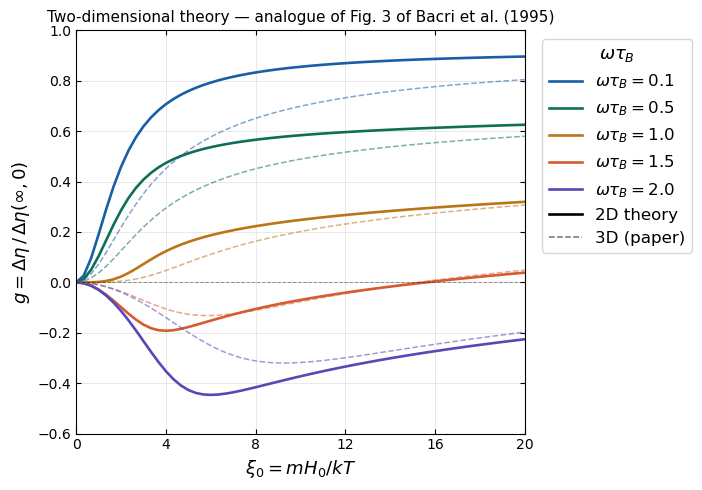

Saved to bacri_fig3_2D.png

Computing the 2D analogue of Fig. 4 (isolines) ...
  omega*tau_B = 0.10 done
  omega*tau_B = 0.36 done
  omega*tau_B = 0.62 done
  omega*tau_B = 0.87 done
  omega*tau_B = 1.13 done
  omega*tau_B = 1.39 done
  omega*tau_B = 1.65 done
  omega*tau_B = 1.91 done
  omega*tau_B = 2.16 done
  omega*tau_B = 2.42 done
  omega*tau_B = 2.68 done
  omega*tau_B = 2.94 done
  omega*tau_B = 3.19 done
  omega*tau_B = 3.45 done
  omega*tau_B = 3.71 done
  omega*tau_B = 3.97 done
  omega*tau_B = 4.23 done
  omega*tau_B = 4.48 done
  omega*tau_B = 4.74 done
  omega*tau_B = 5.00 done


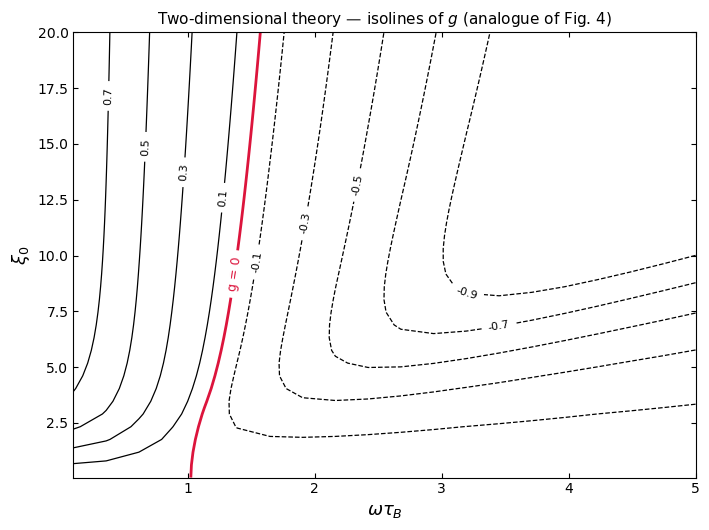

Saved to bacri_fig4_2D.png


In [1]:
"""
=============================================================================
 TWO-DIMENSIONAL THEORETICAL CURVES
 (the 2D analogue of Fig. 3 of Bacri, Perzynski, Shliomis & Burde, PRL 75,
  2128 (1995))

 Method: exactly the one stated in the paper -- effective-field magnetisation
 equation, expanded to first order in the small parameter (Omega * tau_B),
 zeroth-order equation for the effective field xi_e, first-order equation for
 F, fourth-order Runge-Kutta with initial conditions xi_e = xi_0 and F ~ 0,
 then the period average that gives g.

 What changes in 2D:

   3D (paper)                              2D
   ---------------------------------------------------------------------
   L(x)  = coth x - 1/x                    L2(x) = I1(x)/I0(x)
   Eq.(7) tau_B dxi_e/dt                   IDENTICAL IN FORM
          = -(dlnL/dxi_e)^-1 (1 - xi0 cos(wt)/xi_e)
   Eq.(8) tau_B dF/dt                      the factor 1/2 becomes 1
          = 1 - (1/2)(1/L - 1/xi_e) xi0 F cos(wt)      [ = 1/(d-1) ]
   Eq.(9) g = (1/2) xi0 <cos(wt) L F>      g = xi0 <cos(wt) L2 F>
   Eq.(2) dEta = (3/2) eta phi g           dEta = eta phi g   [ = (d/2) ]
   tau_B = 3 eta V / kT                    tau_B = 4 eta V / kT
   zeta_r = 6 eta V                        zeta_r = 4 eta V
   sin^2(beta) factor                      ABSENT (H is always perp. to Omega)

 In BOTH cases g = dEta / dEta(inf,0), so the vertical axis means the same
 thing and the 2D and 3D curves are directly comparable.

 Numerical note: the only change to the reference implementation is that the
 integration is vectorised over the xi_0 grid (all xi_0 values are advanced by
 the same RK4 step simultaneously). This is mathematically identical and about
 60x faster, which matters because L2 = I1/I0 is far more expensive than tanh.

 Requires: numpy, scipy, matplotlib.
 Runtime: ~85 s as written; ~2 min with the isoline map;
 ~30 s with SHOW_3D_COMPARISON = MAKE_ISOLINE_PLOT = RUN_VALIDATION = False.
=============================================================================
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ive          # exponentially scaled I_nu, overflow-safe

# ---------------------------------------------------------------------------
# 0.  Switches
# ---------------------------------------------------------------------------
SHOW_3D_COMPARISON = True     # overlay the 3D curves of the paper (dashed)
MAKE_ISOLINE_PLOT  = True     # also produce the 2D analogue of Fig. 4
RUN_VALIDATION     = True     # analytic cross-checks printed before plotting

TINY = 1e-3                   # series cross-over for the small-argument limits

_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz  # numpy 1.x/2.x


# ---------------------------------------------------------------------------
# 1.  Langevin functions for d = 2 and d = 3, and the auxiliary combinations
#     that appear in Eqs. (7)-(9).  All are safe at x = 0 and for x < 0
#     (the effective field reverses sign every half period).
#
#     L        : L_d(x)                       3D: coth x - 1/x     2D: I1/I0
#     dL       : dL_d/dx                      3D: 1/x^2 - 1/tanh^2 x + 1
#                                             2D: 1 - L^2 - L/x
#     L_over_dL: L/L'      = (dlnL/dx)^-1
#     D        : L/(x L')
#     B        : d/((d-1)x) - 1/((d-1)L)      3D: 3/(2x) - 1/(2L)
#                                             2D: 2/x   - 1/L
# ---------------------------------------------------------------------------
def _core(x, dim):
    """Return L and dL/dx for |x| >= TINY (dummy-safe elsewhere)."""
    ax = np.abs(x)
    axs = np.where(ax < TINY, 1.0, ax)          # keeps the dummy branch finite
    if dim == 3:
        th = np.tanh(axs)
        r = 1.0/th - 1.0/axs
        dr = 1.0/axs**2 - 1.0/th**2 + 1.0
    else:
        r = ive(1, axs)/ive(0, axs)             # = I1/I0, no overflow
        dr = 1.0 - r*r - r/axs                  # from I0'=I1, I1'=I0-I1/x
    return np.sign(x)*r, dr


def L(x, dim=2):
    x = np.asarray(x, float)
    r, _ = _core(x, dim)
    small = np.abs(x) < TINY
    ser = x/3.0 - x**3/45.0 if dim == 3 else x/2.0 - x**3/16.0
    return np.where(small, ser, r)


def dL(x, dim=2):
    x = np.asarray(x, float)
    _, dr = _core(x, dim)
    small = np.abs(x) < TINY
    ser = (1.0/3.0 - x**2/15.0) if dim == 3 else (0.5 - 3.0*x**2/16.0)
    return np.where(small, ser, dr)


def L_over_dL(x, dim=2):
    x = np.asarray(x, float)
    small = np.abs(x) < TINY
    ser = x + (2.0/15.0)*x**3 if dim == 3 else x + x**3/4.0
    return np.where(small, ser, L(x, dim)/dL(x, dim))


def D(x, dim=2):
    """D(x) = L / (x L')"""
    x = np.asarray(x, float)
    ax = np.abs(x); small = ax < TINY
    xs = np.where(small, 1.0, x)
    ser = 1.0 + (2.0/15.0)*ax**2 if dim == 3 else 1.0 + ax**2/4.0
    return np.where(small, ser, L(x, dim)/(xs*dL(x, dim)))


def B(x, dim=2):
    """B(x) = d/((d-1)x) - 1/((d-1)L).  3D: 3/(2x)-1/(2L).  2D: 2/x-1/L."""
    x = np.asarray(x, float)
    ax = np.abs(x); small = ax < TINY
    xs = np.where(small, 1.0, x)
    Lv = L(x, dim); Ls = np.where(small, 1.0, Lv)
    ser = (-x/10.0 + x**3/350.0) if dim == 3 else (-x/4.0 + x**3/96.0)
    c = dim - 1.0
    return np.where(small, ser, dim/(c*xs) - 1.0/(c*Ls))


# ---------------------------------------------------------------------------
# 2.  Transformed ODE system.   Time is measured in units of tau_B, so
#     'omega' below is the dimensionless omega*tau_B.
#
#     Substituting Y = F * L(xi_e) removes the 1/xi_e singularity, exactly as
#     in the 3D reference code.  Using tau_B dL/dt = -L (1 - xi0 cos(wt)/xi_e),
#     which follows from Eq.(7), one gets for BOTH dimensions
#
#         dY/dt = L(xi_e) - Y [ 1 - xi0 cos(wt) B(xi_e) ]
#
#     with the dimension entering only through L and through B.
# ---------------------------------------------------------------------------
def _aux(x, dim):
    """Fused evaluation of (L, L/L', D, B) with a single Bessel/tanh call.
    Mathematically identical to calling L(), L_over_dL(), D(), B() separately;
    used inside the RK4 loop because I1/I0 is expensive."""
    x = np.asarray(x, float)
    ax = np.abs(x); small = ax < TINY
    Lv, dLv = _core(x, dim)
    if dim == 3:
        Lv = np.where(small, x/3.0 - x**3/45.0, Lv)
        dLv = np.where(small, 1.0/3.0 - x**2/15.0, dLv)
        s_LdL = x + (2.0/15.0)*x**3
        s_D = 1.0 + (2.0/15.0)*ax**2
        s_B = -x/10.0 + x**3/350.0
    else:
        Lv = np.where(small, x/2.0 - x**3/16.0, Lv)
        dLv = np.where(small, 0.5 - 3.0*x**2/16.0, dLv)
        s_LdL = x + x**3/4.0
        s_D = 1.0 + ax**2/4.0
        s_B = -x/4.0 + x**3/96.0
    xs = np.where(small, 1.0, x)
    Ls = np.where(small, 1.0, Lv)
    c = dim - 1.0
    LdL = np.where(small, s_LdL, Lv/dLv)
    Dv = np.where(small, s_D, Lv/(xs*dLv))
    Bv = np.where(small, s_B, dim/(c*xs) - 1.0/(c*Ls))
    return Lv, LdL, Dv, Bv


def f_xe(t, xe, xi0, omega, dim=2):
    return -L_over_dL(xe, dim) + D(xe, dim)*xi0*np.cos(omega*t)


def f_Y(t, xe, Y, xi0, omega, dim=2):
    return L(xe, dim) - Y*(1.0 - xi0*np.cos(omega*t)*B(xe, dim))


def f_I(t, Y, omega):
    return Y*np.cos(omega*t)


def _der(t, xe, Y, xi0, omega, dim):
    """(dxe/dt, dY/dt, dI/dt) -- same expressions as f_xe, f_Y, f_I above."""
    c = np.cos(omega*t)
    Lv, LdL, Dv, Bv = _aux(xe, dim)
    return (-LdL + Dv*xi0*c,
            Lv - Y*(1.0 - xi0*c*Bv),
            Y*c)


def rk4_step(t, xe, Y, I, h, xi0, omega, dim=2):
    k1x, k1y, k1i = _der(t,     xe,           Y,           xi0, omega, dim)
    k2x, k2y, k2i = _der(t+h/2, xe+h/2*k1x,   Y+h/2*k1y,   xi0, omega, dim)
    k3x, k3y, k3i = _der(t+h/2, xe+h/2*k2x,   Y+h/2*k2y,   xi0, omega, dim)
    k4x, k4y, k4i = _der(t+h,   xe+h*k3x,     Y+h*k3y,     xi0, omega, dim)
    return (xe + h/6*(k1x + 2*k2x + 2*k3x + k4x),
            Y  + h/6*(k1y + 2*k2y + 2*k3y + k4y),
            I  + h/6*(k1i + 2*k2i + 2*k3i + k4i))


# ---------------------------------------------------------------------------
# 3.  g(xi0, omega*tau_B)
#
#         g = xi0 <cos(wt) L(xi_e) F> / (d-1) = xi0 <Y cos(wt)> / (d-1)
#
#     d = 3 reproduces Eq.(9) of the paper, g = (1/2) xi0 <cos wt L F>.
#
#     The step size is set in ABSOLUTE time (units of tau_B) rather than as a
#     fixed number of steps per period: the stiff rate of the Y equation is
#     ~ xi0 |B| ~ xi0, independent of omega, so a fixed steps-per-period rule
#     silently loses accuracy at low frequency.
# ---------------------------------------------------------------------------
def compute_g(xi0, omega, dim=2, h_target=0.02, n_avg=4, settle_time=30.0):
    xi0 = np.atleast_1d(np.asarray(xi0, float))
    T = 2.0*np.pi/omega
    N = max(600, int(np.ceil(T/h_target)))       # steps per period
    h = T/N
    n_settle = max(2, int(np.ceil(settle_time/T)))

    xe = xi0.copy()
    Y = np.zeros_like(xi0)
    I = np.zeros_like(xi0)
    t = 0.0

    for _ in range(n_settle*N):                  # settle onto the periodic orbit
        xe, Y, _ = rk4_step(t, xe, Y, np.zeros_like(I), h, xi0, omega, dim)
        t += h

    for _ in range(n_avg*N):                     # accumulate the period average
        xe, Y, I = rk4_step(t, xe, Y, I, h, xi0, omega, dim)
        t += h

    return xi0*I/((dim - 1.0)*n_avg*T)


# ---------------------------------------------------------------------------
# 4.  Validation (independent analytic checks -- not part of the plot)
# ---------------------------------------------------------------------------
def g_static_2D(x):
    """Exact stationary-field result of the 2D effective-field theory:
       setting dF/dt = 0 and xi_e = xi0 in Eqs.(2D-5),(2D-6) gives
           F = L/(xi0 - L),   g = xi0 L^2/(xi0 - L)."""
    x = np.abs(np.asarray(x, float))
    Lv = L(x, 2)
    return np.where(x < 1e-8, x*x/2.0, x*Lv**2/(x - Lv + 1e-300))


if RUN_VALIDATION:
    print("VALIDATION")
    print("-"*66)

    # (a) quasi-static limit: as omega -> 0 the ODE result must equal the
    #     CYCLE AVERAGE of the static response evaluated at xi0*cos(wt)
    th = np.linspace(0.0, 2*np.pi, 4001)
    print(" (a) omega*tau_B = 0.05 (quasi-static)  vs  <g_static(xi0 cos wt)>")
    xchk = np.array([0.2, 0.3333, 1.0, 5.0, 20.0])
    ode = compute_g(xchk, 0.05, dim=2, settle_time=40.0)
    for x0, gv in zip(xchk, ode):
        qs = _trapz(g_static_2D(x0*np.cos(th)), th)/(2*np.pi)
        print(f"     xi0={x0:6.3f}   ODE={gv:.5f}   analytic={qs:.5f}"
              f"   diff={abs(gv-qs):.2e}")

    # (b) weak-field limit: g -> xi^2/2 with xi = xi0/sqrt(2)  =>  xi0^2/4
    print(f" (b) weak field  xi0=0.2:  ODE={ode[0]:.6f}   "
          f"xi0^2/4={0.2**2/4:.6f}")

    # (c) step-size convergence
    a = compute_g(8.0, 1.5, dim=2, h_target=0.02)[0]
    b = compute_g(8.0, 1.5, dim=2, h_target=0.01)[0]
    print(f" (c) convergence at (xi0=8, wT=1.5):  h=0.02 -> {a:.6f}, "
          f"h=0.01 -> {b:.6f},  |diff|={abs(a-b):.2e}")

    # (d) the 3D branch must reproduce the published Fig. 3
    g3 = compute_g(np.array([20.0]), 2.0, dim=3)[0]
    print(f" (d) 3D check: g(xi0=20, wT=2) = {g3:+.3f}   "
          f"(paper Fig. 3 reads about -0.20)")
    print("-"*66, "\n")


# ---------------------------------------------------------------------------
# 5.  The curves
# ---------------------------------------------------------------------------
omega_tau_values = [0.1, 0.5, 1.0, 1.5, 2.0]
xi0_arr = np.linspace(0.0, 20.0, 61)

print("Computing the 2D analogue of Fig. 3 of Bacri et al. (1995)")
results2D = {}
for oTau in omega_tau_values:
    print(f"  omega*tau_B = {oTau} ...", flush=True)
    g_vals = compute_g(xi0_arr, oTau, dim=2)
    results2D[oTau] = g_vals
    print(f"    range [{g_vals.min():.3f}, {g_vals.max():.3f}]")

results3D = {}
if SHOW_3D_COMPARISON:
    print("Computing the 3D curves for comparison")
    for oTau in omega_tau_values:
        results3D[oTau] = compute_g(xi0_arr, oTau, dim=3)


# ---------------------------------------------------------------------------
# 6.  Plot
# ---------------------------------------------------------------------------
colors = ['#185FA5', '#0F6E56', '#BA7517', '#D85A30', '#534AB7']

fig, ax = plt.subplots(figsize=(9.2, 5))

for oTau, color in zip(omega_tau_values, colors):
    ax.plot(xi0_arr, results2D[oTau], color=color, linewidth=1.9,
            label=rf'$\omega\tau_B = {oTau}$')
if SHOW_3D_COMPARISON:
    for oTau, color in zip(omega_tau_values, colors):
        ax.plot(xi0_arr, results3D[oTau], color=color, linewidth=1.1,
                linestyle='--', alpha=0.55)
    ax.plot([], [], color='k', linewidth=1.9, label='2D theory')
    ax.plot([], [], color='k', linewidth=1.1, linestyle='--', alpha=0.55,
            label='3D (paper)')

ax.axhline(0, color='black', linewidth=0.7, linestyle='--', alpha=0.4)
ax.set_xlim(0, 20)
ax.set_ylim(-0.6, 1.0)
ax.set_xlabel(r'$\xi_0 = m H_0 / kT$', fontsize=13)
ax.set_ylabel(r'$g = \Delta\eta\,/\,\Delta\eta(\infty,0)$', fontsize=13)
ax.set_xticks([0, 4, 8, 12, 16, 20])
ax.set_yticks(np.arange(-0.6, 1.01, 0.2))
ax.tick_params(direction='in', top=True, right=True)
ax.set_title(r'Two-dimensional theory — analogue of Fig. 3 of Bacri et al. (1995)',
             fontsize=11)
ax.grid(True, linewidth=0.4, alpha=0.5)
ax.legend(fontsize=12, title=r'$\omega\tau_B$', title_fontsize=13,
          loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True)

plt.tight_layout(rect=[0, 0, 0.78, 1])
plt.savefig('bacri_fig3_2D.png', dpi=150)
plt.show()
print("Saved to bacri_fig3_2D.png")


# ---------------------------------------------------------------------------
# 7.  Optional: the 2D analogue of Fig. 4 (isolines of g)
# ---------------------------------------------------------------------------
if MAKE_ISOLINE_PLOT:
    print("\nComputing the 2D analogue of Fig. 4 (isolines) ...")
    xi_grid = np.linspace(0.05, 20.0, 36)
    om_grid = np.linspace(0.1, 5.0, 20)
    Gmap = np.zeros((om_grid.size, xi_grid.size))
    for i, om in enumerate(om_grid):
        Gmap[i, :] = compute_g(xi_grid, om, dim=2)
        print(f"  omega*tau_B = {om:.2f} done", flush=True)

    fig2, ax2 = plt.subplots(figsize=(7.2, 5.4))
    levels = [-0.9, -0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7, 0.9]
    cs = ax2.contour(om_grid, xi_grid, Gmap.T, levels=levels,
                     colors='k', linewidths=0.9)
    ax2.clabel(cs, inline=True, fontsize=8, fmt='%.1f')
    cz = ax2.contour(om_grid, xi_grid, Gmap.T, levels=[0.0],
                     colors='crimson', linewidths=2.0)
    ax2.clabel(cz, inline=True, fontsize=9, fmt='g = 0')
    ax2.set_xlabel(r'$\omega\tau_B$', fontsize=13)
    ax2.set_ylabel(r'$\xi_0$', fontsize=13)
    ax2.set_title('Two-dimensional theory — isolines of $g$ '
                  '(analogue of Fig. 4)', fontsize=11)
    ax2.tick_params(direction='in', top=True, right=True)
    plt.tight_layout()
    plt.savefig('bacri_fig4_2D.png', dpi=150)
    plt.show()
    print("Saved to bacri_fig4_2D.png")